## _*The Deutsch-Jozsa Algorithm*_ 

The [Deutsch-Jozsa algorithm](http://rspa.royalsocietypublishing.org/content/439/1907/553) is one of the earliest examples demonstrating the power of quantum computers. The algorithm deals with guessing the type of a hidden Boolean function given as an oracle. The Boolean function is promised to be either balanced, i.e., whose values are $0$ on half of its inputs, or constant, i.e., whose values are the same on all inputs. 

Classically, in the best case, two queries to the oracle can determine if the hidden Boolean function is balanced; in the worst case, at least half of the inputs must be queried to determine if the hidden Boolean function is constant for all inputs. On the other hand, the Deutsch-Jozsa algorithm can determine the Boolean function with one quantum query.   

The latest version of this notebook is available on https://github.com/qiskit/qiskit-tutorial.

***
### Contributors
Rudy Raymond

## Introduction <a id='introduction'></a>

The algorithm in this notebook follows that in [Cleve et al. 1997](https://arxiv.org/pdf/quant-ph/9708016.pdf). We assume that the input to the oracle $f$ is a $n$-bit string. Namely, for each $x\ in \{0,1\}^n$, the value of $f(x)$ is promised to be either constant, i.e., the same for all $x$, or balanced, i.e., exactly half of the $n$-bit string whose $f(x) = 0$. 

## The Algorithm

The algorithm is quite simple as follows.
1. Prepare two quantum registers initialized to zero. The first is an $n$-qubit reqister for querying the oracle, and the second is a one-qubit register for storing the answer of the oracle
$$
|0\ldots 0\rangle |0\rangle
$$
2. Create the superposition of all input queries in the first register by applying the Hadamard gate to each qubit.
$$
H^{\otimes^n} |0\ldots 0\rangle |0\rangle = \frac{1}{\sqrt{2^n}}\sum_{i=0}^{2^n-1}|i\rangle |0\rangle 
$$
3. Flip the second register and apply the Hadamard gate. This is to store the answer of the oracle in the phase.
$$
\frac{1}{\sqrt{2^n}}\sum_{i=0}^{2^n-1}|i\rangle |0\rangle \rightarrow \frac{1}{\sqrt{2^{n+1}}}\sum_{i=0}^{2^n-1}|i\rangle ( |0\rangle - |1\rangle )
$$
4. Query the oracle
$$
\frac{1}{\sqrt{2^{n+1}}}\sum_{i=0}^{2^n-1}|i\rangle ( |0\rangle - |1\rangle ) \rightarrow \frac{1}{\sqrt{2^{n+1}}}\sum_{i=0}^{2^n-1}(-1)^{f(i)}|i\rangle ( |0\rangle - |1\rangle ) 
$$
5. Apply the Hadamard gate to the first register

6. Measure the first register. If it is non-zero, then conclude that the hidden Boolean function is balanced. Otherwise, conclude that it is constant. 

The correctness of the conclusion of the last step can be explained as follows. 

When the hidden Boolean function is constant, the quantum states before and after querying the oracle are the same. The inverse of the Hadamard gate is the Hadamard gate itself. Thus, by Step 5, we essentially reverse Step 2 to obtain the initial quantum state of all-zero at the first register.  

When the hidden Boolean function is balanced, the quantum state after querying the oracle is orthogonal to the quantum state before querying the oracle. Thus, by Step 5, when reverting the operation, we must end up with a quantum state that is orthogonal to the initial quantum state of all-zero at the first register. This means we should never obtain the all-zero state. 

# Deutsch–Jozsa algorithm: step-by-step analysis

## 1. The problem

We are given a black-box function $f:\{0,1\}^n \to \{0,1\}$ together with a **promise**: $f$ is either

- **constant**: $f(x)$ takes the same value for every input $x$, or
- **balanced**: $f(x)=0$ for exactly half of the inputs and $f(x)=1$ for the other half.

The task is to decide which one it is.

- A deterministic classical algorithm needs $2^{n-1}+1$ queries in the worst case.
- The Deutsch–Jozsa algorithm needs **one** query to $f$.

Throughout, bitstrings are written in Qiskit's order, $x = x_{n-1}\cdots x_1x_0$, so qubit $0$ holds the rightmost bit.

---

## 2. The circuit at a glance

We use $n$ input qubits plus one output qubit.

1. Start in $|0\rangle^{\otimes n}\,|1\rangle$.
2. Apply $H$ to all $n+1$ qubits.
3. Apply the oracle $U_f$, defined by $U_f|x\rangle|b\rangle = |x\rangle|b\oplus f(x)\rangle$.
4. Apply $H$ to the $n$ input qubits.
5. Measure the $n$ input qubits.

**Decision rule:** all outcomes $0$ means $f$ is constant; any other outcome means $f$ is balanced.

---

## 3. The one tool we need: the Hadamard formula

On a single qubit, $H|0\rangle=\frac{1}{\sqrt2}(|0\rangle+|1\rangle)$ and $H|1\rangle=\frac{1}{\sqrt2}(|0\rangle-|1\rangle)$. Both cases fit into one formula, for $a\in\{0,1\}$:

$$
H|a\rangle = \frac{1}{\sqrt2}\sum_{b\in\{0,1\}} (-1)^{ab}\,|b\rangle .
$$

The sign is $-1$ only when $a=b=1$.

For $n$ qubits, $H^{\otimes n}$ applies one Hadamard to each qubit, and the result is a product of $n$ such sums:

$$
\begin{aligned}
H^{\otimes n}|x_{n-1}\cdots x_0\rangle
&= \big(H|x_{n-1}\rangle\big)\otimes\cdots\otimes\big(H|x_0\rangle\big)\\[4pt]
&= \left(\tfrac{1}{\sqrt2}\sum_{y_{n-1}\in\{0,1\}}(-1)^{x_{n-1}y_{n-1}}|y_{n-1}\rangle\right)\otimes\cdots\otimes\left(\tfrac{1}{\sqrt2}\sum_{y_0\in\{0,1\}}(-1)^{x_0y_0}|y_0\rangle\right)\\[4pt]
&= \frac{1}{\sqrt{2^n}}\sum_{y\in\{0,1\}^n}(-1)^{x_{n-1}y_{n-1}+\cdots+x_0y_0}\,|y_{n-1}\cdots y_0\rangle .
\end{aligned}
$$

Expanding the product gives one term for every bitstring $y$. The prefactors multiply to $1/\sqrt{2^n}$, and the signs multiply, so their exponents add. Only the parity of the exponent matters, so we write it as the inner product $x\cdot y = x_{n-1}y_{n-1}\oplus\cdots\oplus x_0y_0$:

$$
\boxed{\,H^{\otimes n}|x\rangle=\frac{1}{\sqrt{2^n}}\sum_{y\in\{0,1\}^n}(-1)^{x\cdot y}\,|y\rangle\,}
$$

---

## 4. Following the state, step by step

### Step 0: initial state

$$
|\psi_0\rangle = |0\rangle^{\otimes n}\,|1\rangle
$$

### Step 1: first layer of Hadamards

On the output qubit, $H|1\rangle = |-\rangle = \frac{1}{\sqrt2}(|0\rangle-|1\rangle)$. On the input qubits, the formula above with $x=0\cdots0$ makes every sign $+$:

$$
|\psi_1\rangle = |-\rangle \otimes \frac{1}{\sqrt{2^n}}\sum_{x\in\{0,1\}^n}|x\rangle
$$

All $2^n$ possible inputs are now present at once with equal amplitude, and the output qubit is in $|-\rangle$.

### Step 2: the oracle (phase kickback)

Look at what $U_f$ does to one basis input $|x\rangle$ when the output qubit is $|-\rangle$:

$$
U_f\,|x\rangle|-\rangle
= |x\rangle\,\frac{|f(x)\rangle-|1\oplus f(x)\rangle}{\sqrt2}
= (-1)^{f(x)}\,|x\rangle|-\rangle .
$$

- If $f(x)=0$, the two terms stay in place and nothing changes.
- If $f(x)=1$, the two terms swap places, which produces an overall factor of $-1$.

So the value of $f(x)$ is not written into the output qubit. It is written into the **sign** of $|x\rangle$, and the output qubit stays in $|-\rangle$. Applying this to every term of the superposition:

$$
|\psi_2\rangle = |-\rangle \otimes \frac{1}{\sqrt{2^n}}\sum_{x\in\{0,1\}^n}(-1)^{f(x)}\,|x\rangle
$$

At this point a measurement would still give a uniformly random $x$, because signs do not affect probabilities. The information about $f$ is hidden in the phases.

### Step 3: second layer of Hadamards (on the input qubits only)

$H^{\otimes n}$ is linear, so we apply it to each term of the sum and then use the formula from Section 3 for $H^{\otimes n}|x\rangle$:

$$
|\psi_3\rangle
= |-\rangle \otimes \frac{1}{\sqrt{2^n}}\sum_{x}(-1)^{f(x)}\left[\frac{1}{\sqrt{2^n}}\sum_{y}(-1)^{x\cdot y}|y\rangle\right]
= |-\rangle \otimes \frac{1}{2^n}\sum_{x}\sum_{y}(-1)^{f(x)+x\cdot y}\,|y\rangle .
$$

The double sum has two origins. The sum over $x$ comes from the superposition in Step 2. The sum over $y$ comes from expanding each $H^{\otimes n}|x\rangle$. The two signs multiply, so their exponents add, and the two prefactors multiply to $1/2^n$.

Grouping by the output $y$, the **amplitude of $|y\rangle$** is

$$
\alpha_y = \frac{1}{2^n}\sum_{x\in\{0,1\}^n}(-1)^{f(x)+x\cdot y}.
$$

### Step 4: the probability of measuring $0\cdots0$

We only need $y=0\cdots0$. Then $x\cdot y=0$ for every $x$, so the sign from the Hadamards disappears and

$$
\alpha_{0\cdots0}=\frac{1}{2^n}\sum_{x\in\{0,1\}^n}(-1)^{f(x)},
$$

which is simply the **average of the signs** $(-1)^{f(x)}$.

- **$f$ constant.** Every term is the same, $(-1)^c$ with $c\in\{0,1\}$, so the sum is $\pm 2^n$ and
$$
\Pr[0\cdots0]=\left|\frac{\pm 2^n}{2^n}\right|^2 = 1 .
$$
- **$f$ balanced.** Exactly $2^{n-1}$ terms equal $+1$ and exactly $2^{n-1}$ terms equal $-1$, so they cancel completely:
$$
\Pr[0\cdots0]=\left|\frac{2^{n-1}-2^{n-1}}{2^n}\right|^2 = 0 .
$$

In short:

$$
\Pr[\text{all outcomes } 0]=\left|\frac{1}{2^n}\sum_{x}(-1)^{f(x)}\right|^2=
\begin{cases}
1 & f \text{ constant}\\
0 & f \text{ balanced}
\end{cases}
$$

This is a perfect, error-free answer, as long as the promise holds. For a function that is neither constant nor balanced, the probability would be strictly between $0$ and $1$ and the algorithm would not give a clean answer.

---

## 5. A concrete example with $n=2$

Write the four amplitudes in the order $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ (the output qubit stays in $|-\rangle$ and is left out).

| Step | $f\equiv 0$ (constant) | $f=(0,1,1,0)$ (balanced) |
|---|---|---|
| After first $H$ layer | $(\tfrac12,\tfrac12,\tfrac12,\tfrac12)$ | $(\tfrac12,\tfrac12,\tfrac12,\tfrac12)$ |
| After oracle (multiply by $(-1)^{f(x)}$) | $(\tfrac12,\tfrac12,\tfrac12,\tfrac12)$ | $(\tfrac12,-\tfrac12,-\tfrac12,\tfrac12)$ |
| After second $H$ layer | $(1,0,0,0)$ | $(0,0,0,1)$ |
| Measured | $00$ → constant | $11$ → balanced |

The reason for the last row comes from the first row of the matrix $H^{\otimes 2}$, which is all $+$ signs. The amplitude of $|00\rangle$ is therefore $\tfrac12\times$(sum of the four amplitudes before the layer):

- constant: $\tfrac12\left(\tfrac12+\tfrac12+\tfrac12+\tfrac12\right)=1$
- balanced: $\tfrac12\left(\tfrac12-\tfrac12-\tfrac12+\tfrac12\right)=0$

---

## 6. Summary

| Idea | What it does |
|---|---|
| Superposition (first $H$ layer) | Queries all $2^n$ inputs in a single oracle call |
| Output qubit in $|-\rangle$ | Turns "flip the output when $f(x)=1$" into a phase $(-1)^{f(x)}$ |
| Oracle | Writes $f$ into the signs, which measurement cannot see yet |
| Second $H$ layer | Makes the signs interfere |
| Amplitude of $|0\cdots0\rangle$ | Equals the average of $(-1)^{f(x)}$: $\pm1$ if constant, $0$ if balanced |

**Final rule:** measure the $n$ input qubits. If every bit is $0$, $f$ is constant. Otherwise, $f$ is balanced.

## The Circuit <a id="circuit"></a>

We now implement the Deutsch-Jozsa algorithm with Qiskit by first preparing the environment.

In [2]:
%pip install matplotlib

  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl (70 kB)
  Using cached pillow-12.3.0-cp310-cp310-win_amd64.whl (7.2 MB)
  Using cached fonttools-4.65.0-cp310-cp310-win_amd64.whl (1.6 MB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\quantum algorithms\projects\venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [1]:
# useful additional packages 
import numpy as np
import matplotlib.pyplot as plt

# importing Qiskit
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


#from qiskit_ibm_runtime import SamplerV2 as Sampler
#from qiskit_ibm_runtime import QiskitRuntimeService

We first set the length of the $n$-bit string. 

In [2]:
n = 10 # the length of the first register for querying the oracle 

We then use Qiskit to program the algorithm.

In [17]:
# Choose a type of oracle at random. With probability half it is constant, 
# and with the same probability it is balanced
oracleType, oracleValue = np.random.randint(2), np.random.randint(2)

if oracleType == 0:
    print("The oracle returns a constant value ", oracleValue)
else:
    print("The oracle returns a balanced function")
    a = np.random.randint(1,2**n) # this is a hidden parameter for balanced oracle. 

# Creating registers
# n qubits for querying the oracle and one qubit for storing the answer
qr = QuantumRegister(n+1) #all qubits are initialized to zero
# for recording the measurement on the first register
cr = ClassicalRegister(n, name='res')

circuitName = "DeutschJozsa"
djCircuit = QuantumCircuit(qr, cr)

# Create the superposition of all input queries in the first register by applying the Hadamard gate to each qubit.
for i in range(n):
    djCircuit.h(qr[i])

# Flip the second register and apply the Hadamard gate.
djCircuit.x(qr[n])
djCircuit.h(qr[n])
    
# Apply barrier to mark the beginning of the oracle
djCircuit.barrier()

if oracleType == 0:#If the oracleType is "0", the oracle returns oracleValue for all input. 
    if oracleValue == 1:
        djCircuit.x(qr[n])
    else:
        djCircuit.id(qr[n])
else: #Here i changed the condition to something different compared to the original code. The idea is that the first bit of each bitstring is enough to create a balanced function (half of the bitstrings will have 0 as the first bit and the other half will have 1 as the first bit).
    for i in range(n):
        if (i & 1):
            djCircuit.cx(qr[i], qr[n])
        
# Apply barrier to mark the end of the oracle
djCircuit.barrier()

# Apply Hadamard gates after querying the oracle
for i in range(n):
    djCircuit.h(qr[i])
    
# Measurement
djCircuit.barrier()
for i in range(n):
    djCircuit.measure(qr[i], cr[i])

The oracle returns a constant value  1


## Experiment with Simulators

We can run the above circuit on the simulator. 

First, we draw the circuit.

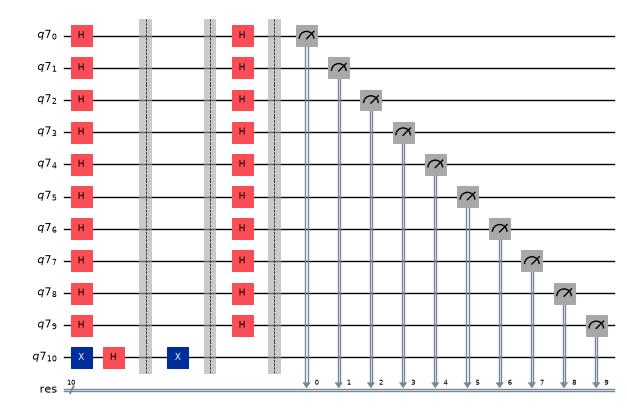

In [18]:
#draw the circuit
djCircuit.draw(output='mpl',scale=0.5)

We then run the circuit on the simulator.

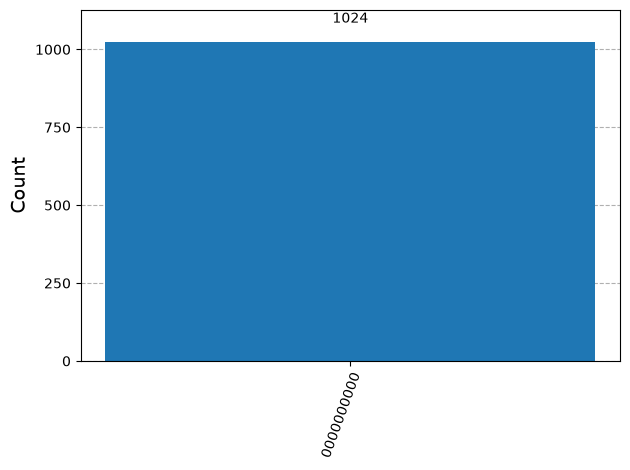

In [19]:
sampler = StatevectorSampler()
job = sampler.run([djCircuit])
results = job.result()
plot_histogram(results[0].data.res.get_counts())

Repeating the above experiments, we can see that the result of the measurement is an all-zero bitstring if the oracle returns a constant value, or a non-zero bitstring otherwise.

## Experiment with Real Devices

We can run the circuit on the real device as below. However, notice that because the real devices are noisy, we cannot obtain the type of oracles with certainty, unlike when running the experiments with simulators. The Deutsch-Jozsa algorithm only shows the superiority of quantum computers against exact classical algorithms; when allowing some error, classically we can determine the type of the hidden Boolean function with a constant number of queries. This is asymptotically the same as the case with quantum computers. 

In [6]:
service = QiskitRuntimeService(channel="ibm_quantum")
backend = service.least_busy(operational=True, simulator=False)
print(backend.name)
target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

isa_circuit = pm.run(djCircuit)
#isa_circuit.draw(output='mpl',scale=0.5)

ibm_brisbane


In [8]:
sampler = Sampler(mode=backend)

job = sampler.run([isa_circuit]).result()
id = job.job_id()
print(id)

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
job = service.job(id)
job_result = job.result()
counts = job_result[0].data.res.get_counts()
#plot_histogram(counts)

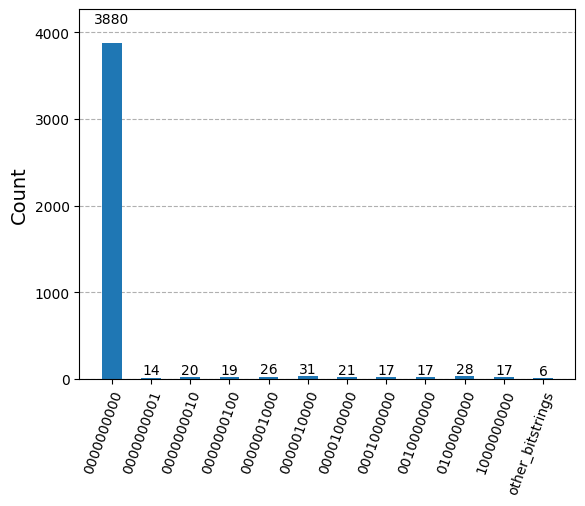

In [4]:
threshold = int(0.01 * 1024) # the threshold of plotting significant measurements, 1% of the default number of shots, 1024
filteredAnswer = {k: v for k,v in counts.items() if v >= threshold} # filter the answer for better view of plots

removedCounts = np.sum([ v for k,v in counts.items() if v < threshold ]) # number of counts removed 
filteredAnswer['other_bitstrings'] = removedCounts  # the removed counts are assigned to a new index

plot_histogram(filteredAnswer)

In [5]:
! pip freeze | grep qiskit

qiskit==1.1.0
qiskit-aer==0.14.2
qiskit-algorithms==0.3.0
qiskit-ibm-runtime==0.25.0
qiskit-machine-learning==0.7.2
qiskit-nature==0.7.2
qiskit-nature-pyscf==0.4.0
qiskit-qasm3-import==0.5.0
qiskit-transpiler-service==0.4.5
